In [1]:
%matplotlib ipympl

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib import cm
import make_HPO_pes as mpes

In [3]:
HPO_PES_file = 'HPO_PES_f12b_10th_order.txt'
print(mpes.get_non_linear_p(HPO_PES_file))

[ 1.48332874e+00  1.45450247e+00  1.04379627e+02  1.50379294e+00
  1.68800000e+00  1.50000000e+01  1.00000000e+01  0.00000000e+00
  0.00000000e+00 -9.59562658e-03]


In [4]:
p, orders = mpes.get_coeffs_orders(HPO_PES_file)
nonlin_p = mpes.get_non_linear_p(HPO_PES_file)
pes = mpes.get_pes(p, nonlin_p.copy(), orders)

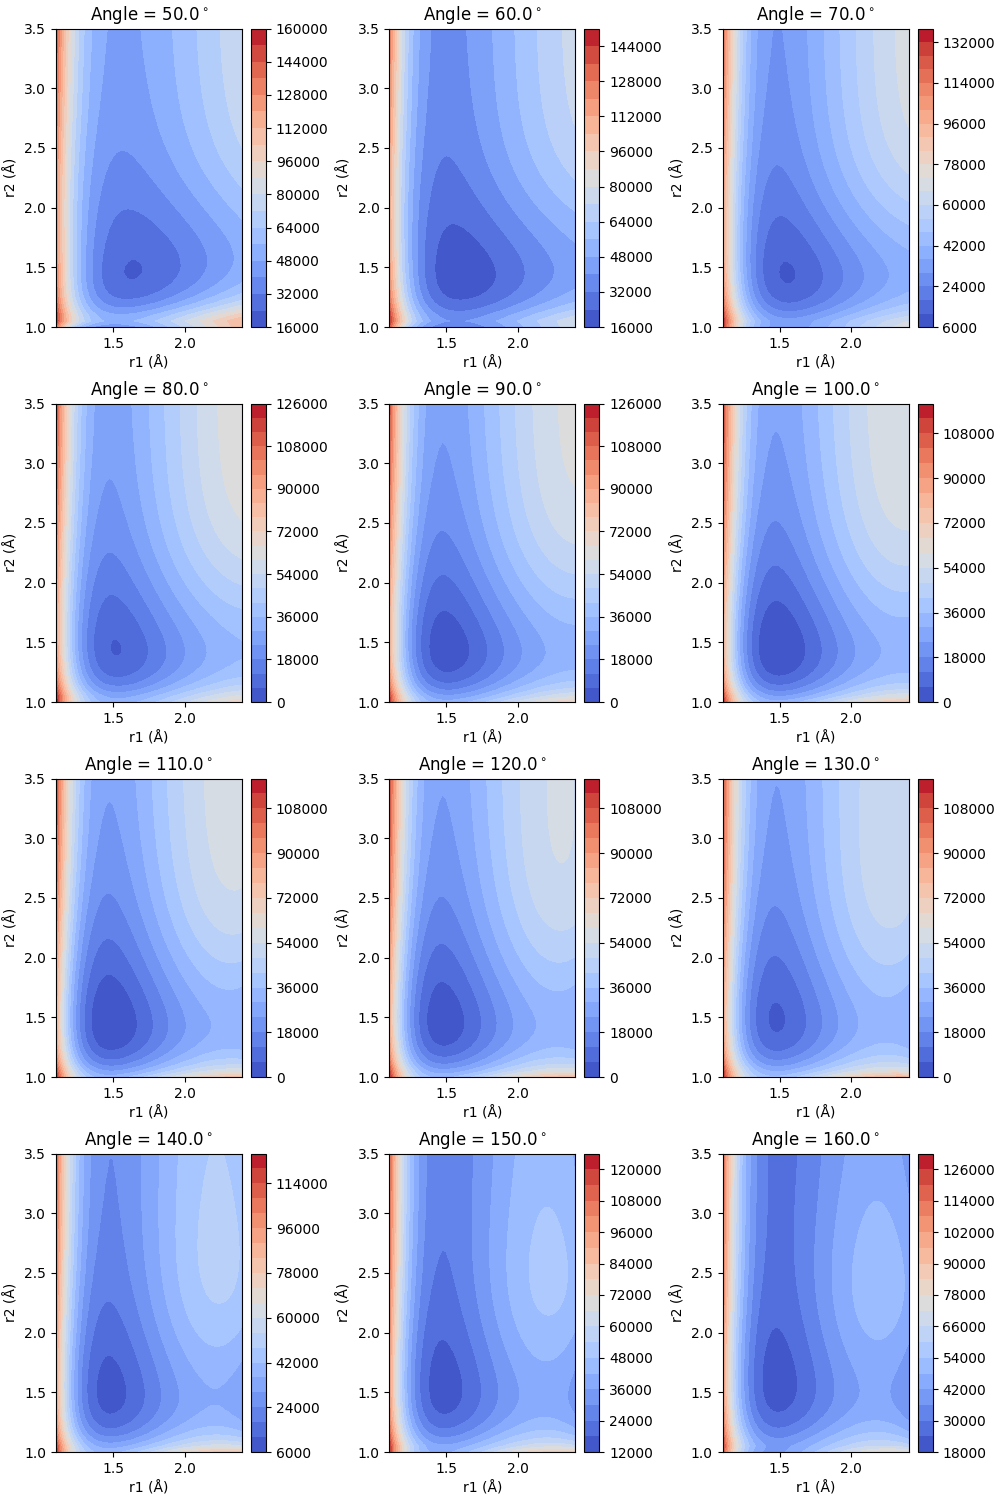

In [5]:
equilibriums = np.array([0.148350247959E+01,
                         0.145448124026E+01,
                         0.104386978891E+03])

r1_grid = np.linspace(1.1,2.4, 50)
r2_grid = np.linspace(1.0,3.5, 50)
a_grid = np.arange(50.0, 161.0, 10)

fig, ax = plt.subplots(4, 3, figsize=(10, 15),
                       constrained_layout=True)
ax = ax.flatten()

for i in range(len(a_grid)):
    angle = a_grid[i]
    r1r2_mesh = np.meshgrid(r1_grid, r2_grid)
    r1_mesh = r1r2_mesh[0]
    r2_mesh = r1r2_mesh[1]

    geometry_r1r2= np.zeros((len(r1_grid)*len(r2_grid), 
                           3) )
    geometry_r1r2[:, 0] = r1_mesh.flatten()
    geometry_r1r2[:, 1] = r2_mesh.flatten()
    geometry_r1r2[:, 2] = angle

    pes_vals = pes(geometry_r1r2)
    pes_vals = np.reshape(pes_vals, 
                        (len(r1_grid), len(r2_grid)) #shape 
                       )
    

    ax[i].set_title(f'Angle = {angle:.1f}$^\\circ$')
    ax[i].set_xlabel('r1 (Å)')
    ax[i].set_ylabel('r2 (Å)')

    contour = ax[i].contourf(
    r1_mesh, r2_mesh, pes_vals,
    levels=20,
    cmap=cm.coolwarm,
    )
    plt.colorbar(contour, ax=ax[i])

#geometry1d = np.zeros((100, 3))
#for j in range(3):
#    geometry1d[:, j] = equilibriums[j]
#
#geometry1d[:, 1] = np.linspace(1.0,3.5, 100)
#
#fig, ax = plt.figure()
#plt.plot(geometry1d[:, 1], pes(geometry1d), label='PES')

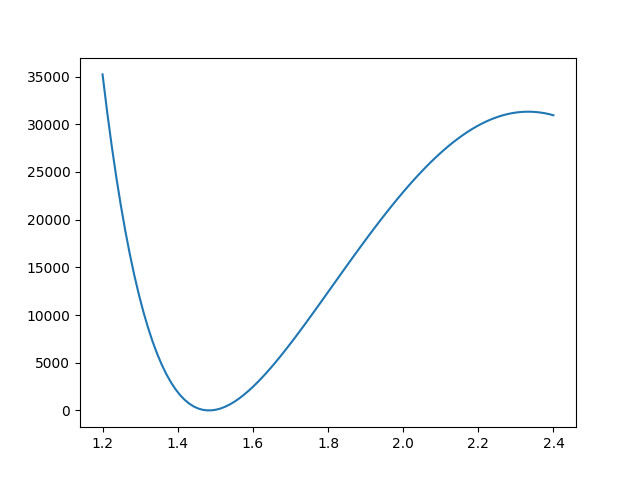

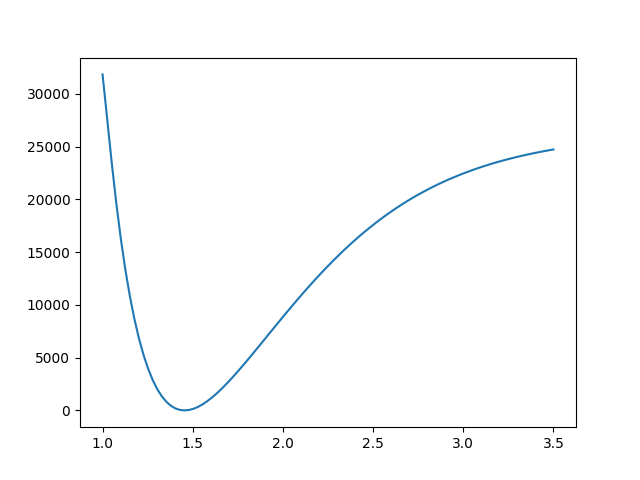

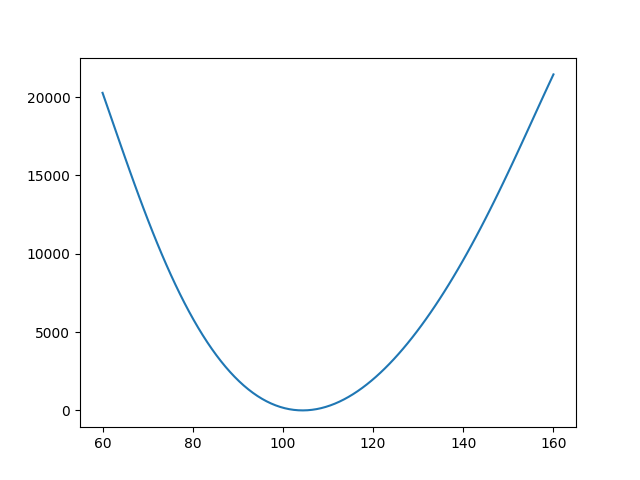

In [6]:
equilibriums = np.array([0.148350247959E+01,
                         0.145448124026E+01,
                         0.104386978891E+03])

#equilibriums = np.array([1.583,
#                         0.145448124026E+01,
#                         140.0])

x_bot = [1.2, 1.0, 60]
x_top = [2.4, 3.5, 160]

    
for k in range(3):
    geometry1d = np.zeros((100, 3))
    for j in range(3):
        geometry1d[:, j] = equilibriums[j]

    geometry1d[:, k] = np.linspace(x_bot[k], x_top[k], 100)
    plt.figure()
    plt.plot(geometry1d[:, k], pes(geometry1d), label='PES')
